# 03 · Gaussian Mixture From Scratch — the showpiece

Unlabeled continuous data from three hidden Gaussians. We build EM **from scratch** —
an explicit E-step (responsibilities), an explicit M-step (weighted mean / covariance /
weight updates), and a log-likelihood we watch climb — and recover every component's
mean, covariance, and weight. Then we check the recovery against the planted truth and
against scikit-learn.

This is the moment structure is estimated from data that never carried labels.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## The data: three hidden Gaussians, labels discarded

figure -> outputs/figures/nb03_data.png
data   -> outputs/data/nb03_inputs.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb03_inputs.json')

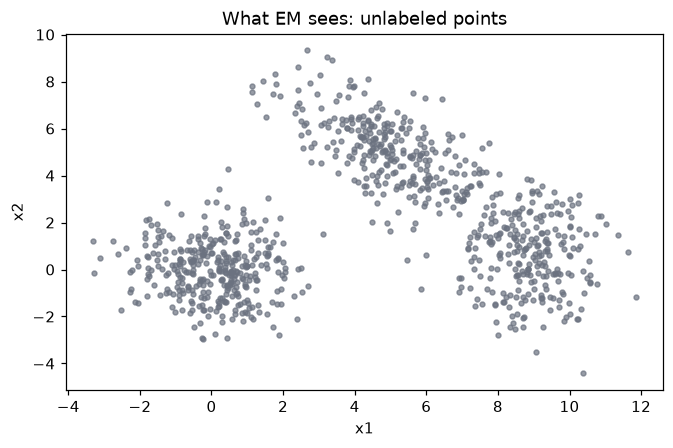

In [2]:
from src.datasets.mixtures import make_gaussian_mixture

PLANTED = {
    "weights": [0.40, 0.35, 0.25],
    "means": [[0.0, 0.0], [5.0, 5.0], [9.0, 0.5]],
    "covariances": [
        [[1.4, 0.0], [0.0, 1.4]],
        [[2.2, -1.4], [-1.4, 2.2]],   # elongated / correlated
        [[1.0, 0.0], [0.0, 2.6]],
    ],
    "n_samples": 900,
    "seed": 11,
}

X, true_labels, truth = make_gaussian_mixture(
    PLANTED["n_samples"], PLANTED["weights"], PLANTED["means"], PLANTED["covariances"],
    seed=PLANTED["seed"],
)
K = len(PLANTED["weights"])

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], s=10, color="#6b7280", alpha=0.7)
ax.set_title("What EM sees: unlabeled points"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
savefig(fig, "nb03_data")
savejson("nb03_inputs", {"description": "Planted 2-D 3-component Gaussian mixture.", "planted_truth": PLANTED})


## The whole algorithm, from scratch

A few dozen lines. The **E-step** computes responsibilities (how much each component
owns each point) with log-sum-exp for numerical stability. The **M-step** re-estimates
each component's weight, mean, and covariance using those responsibilities as weights.


In [3]:
from src.diagnostics.init_strategies import kmeans_plus_plus
from src.diagnostics.likelihood import logsumexp


def log_gaussian(X, mean, cov):
    d = X.shape[1]
    _, logdet = np.linalg.slogdet(cov)
    prec = np.linalg.inv(cov)
    diff = X - mean
    maha = np.einsum("ij,jk,ik->i", diff, prec, diff)
    return -0.5 * (d * np.log(2 * np.pi) + logdet + maha)


def e_step(X, w, mu, cov):
    logp = np.stack([np.log(w[k]) + log_gaussian(X, mu[k], cov[k]) for k in range(len(w))], axis=1)
    lognorm = logsumexp(logp, axis=1)
    return np.exp(logp - lognorm[:, None]), float(lognorm.sum())


def m_step(X, r, reg=1e-6):
    N, d = X.shape
    nk = r.sum(0) + 1e-12
    w = nk / N
    mu = (r.T @ X) / nk[:, None]
    cov = np.empty((r.shape[1], d, d))
    for k in range(r.shape[1]):
        diff = X - mu[k]
        cov[k] = (r[:, k:k + 1] * diff).T @ diff / nk[k] + reg * np.eye(d)
    return w, mu, cov


# --- initialize deliberately broad, then let EM tighten the components ---
init_rng = np.random.default_rng(0)
mu = kmeans_plus_plus(X, K, init_rng)
cov = np.stack([np.eye(2) * X.var(0).mean() for _ in range(K)])
w = np.full(K, 1.0 / K)

snapshots, history = [], []
for it in range(80):
    r, ll = e_step(X, w, mu, cov)
    history.append(ll)
    snapshots.append({"iter": it, "w": w.copy(), "mu": mu.copy(), "cov": cov.copy(),
                      "labels": r.argmax(1)})
    w, mu, cov = m_step(X, r)
    if it > 0 and ll - history[-2] < 1e-6:
        break
r, ll = e_step(X, w, mu, cov)
history.append(ll)
snapshots.append({"iter": len(history) - 1, "w": w.copy(), "mu": mu.copy(), "cov": cov.copy(),
                  "labels": r.argmax(1)})
history = np.array(history)
print(f"converged in {len(history) - 1} iterations, final log-likelihood = {history[-1]:.1f}")


converged in 76 iterations, final log-likelihood = -3874.5


## The components separate out of the tangle

figure -> outputs/figures/nb03_iterations.png
data   -> outputs/data/nb03_snapshots.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb03_snapshots.json')

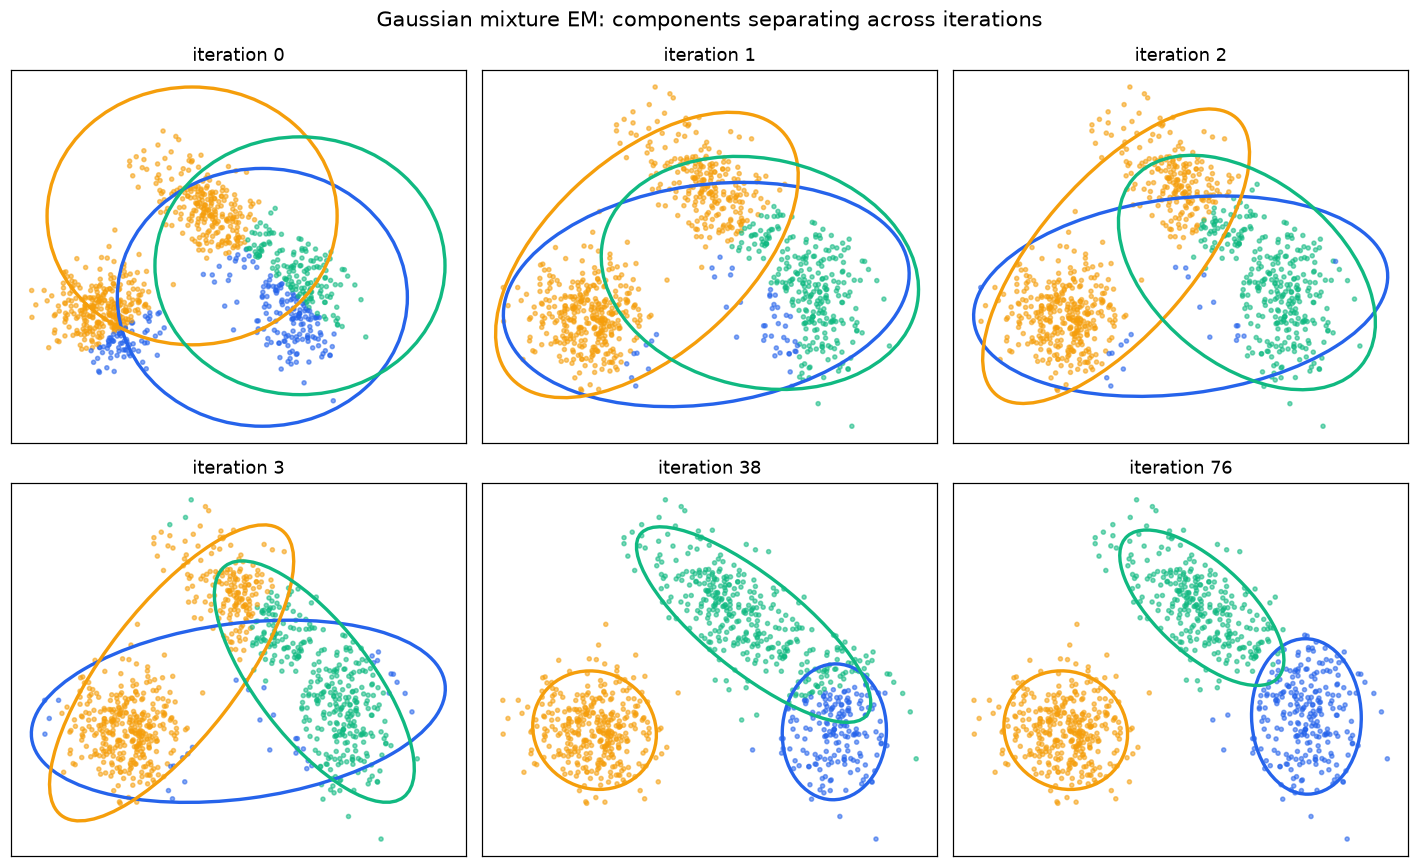

In [4]:
from matplotlib.patches import Ellipse

COLORS = ["#2563eb", "#f59e0b", "#10b981"]


def draw_ellipse(ax, mean, cov, color, nsig=2.0):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    width, height = 2 * nsig * np.sqrt(vals)
    ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, edgecolor=color, lw=2.2))


frame_ids = list(dict.fromkeys([0, 1, 2, 3, len(snapshots) // 2, len(snapshots) - 1]))
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, fid in zip(axes.ravel(), frame_ids):
    snap = snapshots[fid]
    ax.scatter(X[:, 0], X[:, 1], s=7, c=[COLORS[c] for c in snap["labels"]], alpha=0.55)
    for k in range(K):
        draw_ellipse(ax, snap["mu"][k], snap["cov"][k], COLORS[k])
    ax.set_title(f"iteration {snap['iter']}")
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.ravel()[len(frame_ids):]:
    ax.axis("off")
fig.suptitle("Gaussian mixture EM: components separating across iterations", fontsize=14)
fig.tight_layout()
savefig(fig, "nb03_iterations")

savejson("nb03_snapshots", {
    "frames": [{"iter": int(snapshots[f]["iter"]), "weights": snapshots[f]["w"],
                "means": snapshots[f]["mu"], "covariances": snapshots[f]["cov"]}
               for f in frame_ids],
})


## The log-likelihood climbs monotonically — every single step

figure -> outputs/figures/nb03_loglik.png
monotone: True
data   -> outputs/data/nb03_loglik_history.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb03_loglik_history.json')

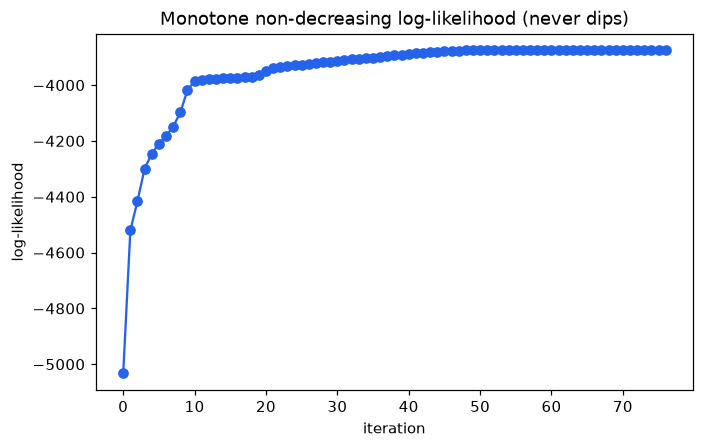

In [5]:
from src.diagnostics.likelihood import is_monotone_nondecreasing

assert is_monotone_nondecreasing(history, atol=1e-6), "log-likelihood decreased!"

fig, ax = plt.subplots()
ax.plot(history, marker="o", color="#2563eb")
ax.set_xlabel("iteration"); ax.set_ylabel("log-likelihood")
ax.set_title("Monotone non-decreasing log-likelihood (never dips)")
savefig(fig, "nb03_loglik")
print("monotone:", bool(is_monotone_nondecreasing(history, atol=1e-6)))
savejson("nb03_loglik_history", {"log_likelihood": history, "monotone": True})


## Recovery: against the planted truth, and against scikit-learn

In [6]:
from src.evaluation.recovery import match_components, parameter_recovery
from src.evaluation.vs_sklearn import compare_gmm

rec = parameter_recovery(truth, w, mu, cov)
perm = match_components(truth.means, mu)
comp = compare_gmm(X, K, random_state=0, n_init=10)

print("max mean error   :", round(rec["max_mean_error"], 3))
print("max weight error :", round(rec["max_weight_error"], 3))
print("max cov error    :", round(rec["max_cov_error"], 3))
print(f"avg log-lik  ours={comp['ours_avg_loglik']:.4f}  sklearn={comp['sklearn_avg_loglik']:.4f}"
      f"  |diff|={comp['abs_diff']:.2e}")

savejson("nb03_results", {
    "planted": {"weights": truth.weights, "means": truth.means, "covariances": truth.covariances},
    "recovered": {"weights": w[perm], "means": mu[perm], "covariances": cov[perm]},
    "recovery_errors": {k: rec[k] for k in ["max_mean_error", "max_weight_error", "max_cov_error"]},
    "vs_sklearn": comp,
    "n_iterations": int(history.size - 1),
})


max mean error   : 0.128
max weight error : 0.026
max cov error    : 0.402
avg log-lik  ours=-4.3050  sklearn=-4.3050  |diff|=5.33e-07
data   -> outputs/data/nb03_results.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb03_results.json')

## Takeaway

From nothing but unlabeled points, EM recovered three populations — including the
elongated, correlated component that a distance-based method would mangle. The soft
responsibilities and full covariances are exactly what a Gaussian mixture buys you over
K-Means, and exactly why GMM beat K-Means in the clustering benchmarks.

**Next:** `04_kmeans_is_hard_em` — force the responsibilities to all-or-nothing and the
very same loop becomes K-Means.


In [7]:
savejson("nb03_narrative", {
    "title": "Gaussian Mixture From Scratch",
    "e_step": "Responsibilities r_ik via log-sum-exp (soft membership of point i in component k).",
    "m_step": "Weighted re-estimation of each component's weight, mean, and full covariance.",
    "key_result": "Recovered 3 components (means, covariances, weights) from unlabeled data; matches sklearn.",
    "figures": {
        "nb03_data": "The unlabeled input points.",
        "nb03_iterations": "Components separating across EM iterations (2-sigma ellipses).",
        "nb03_loglik": "Monotone non-decreasing log-likelihood.",
    },
})


data   -> outputs/data/nb03_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb03_narrative.json')